In [1]:
import pandas as pd
import numpy as np
import json
from config import *
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm
import textwrap
from scipy.stats import pearsonr

# Dataset View

In [2]:
dataset = pd.read_csv("raw_data/All_Dataset.csv")
huesken = dataset[dataset["sources"] == "Huesken"]
huesken.head(3)

,Unnamed: 0,A,B,efficacy,Label,siRNA_seq,mRNA_seq,sources
0,0,A1,BD135193,0.462,0.0,CTAATATGTTAATTGATTTAT,ATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTGAGTTG,Huesken
1,1,A2,BD135193,0.384,0.0,AATATGTTAATTGATTTATAC,AGATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTG...,Huesken
2,2,A3,BD135193,0.514,0.0,GATTTATACAATTCCTTTCAA,CTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAAATCAATTA...,Huesken


<Axes: xlabel='efficacy', ylabel='Count'>

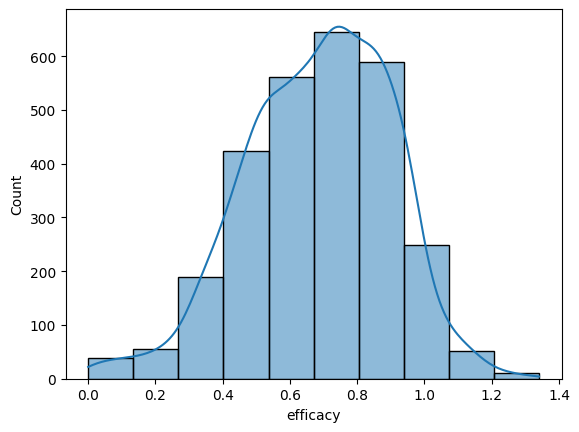

In [3]:
sns.histplot(dataset, x="efficacy", kde=True, bins=10)

# Leave One Target Out

In [5]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.head(5)

,name,representation,model,metric,value
0,BD135193,GC_count,SVC,roc_auc,0.657407
1,BD135193,GC_count,SVC,pr_auc,0.770932
2,BD135193,GC_count,SVC,precision,0.619048
3,BD135193,GC_count,SVC,recall,0.975000
4,BD135193,GC_count,SVC,fscore,0.757282


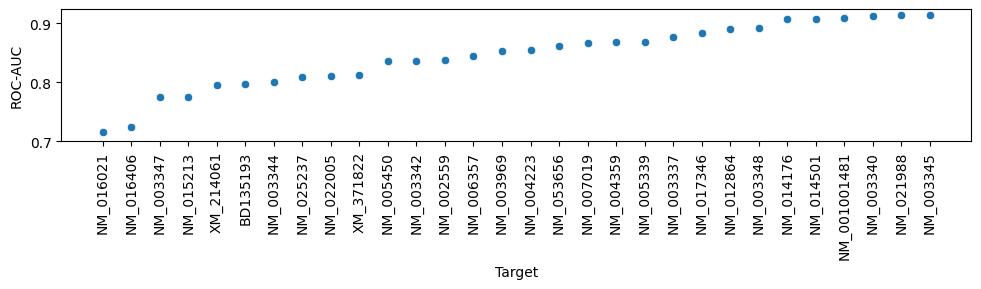

In [10]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["representation"] == "zcurve")
    & (df["metric"] == "roc_auc")
]

filtered_df = filtered_df.sort_values(by="value")
mean_roc = np.round(np.mean(filtered_df["value"]), 3)
# Scatter line plot
plt.figure(figsize=(10, 3))
sns.scatterplot(data=filtered_df, x="name", y="value")

plt.xticks(rotation=90)
plt.xlabel("Target")
plt.ylabel("ROC-AUC")
plt.ylim(bottom=0.7)
plt.tight_layout()
plt.show()

# Sliding Window

In [13]:
rows = []
outpath = "sliding_window_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "win_len": (b := filename[:-5]).split("_")[1],
                            "window_start": int((b := filename[:-5]).split("_")[3]) + 1,
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df = df[(df["model"] == "LGR") & (df["metric"] == "roc_auc")]
df_avg = df.groupby(["win_len", "window_start"])["value"].mean().reset_index()
df_avg.head(5)
df.head(2)

,name,win_len,window_start,model,metric,value
10,BD135193,3,5,LGR,roc_auc,0.506481
45,NM_001001481,3,5,LGR,roc_auc,0.785714


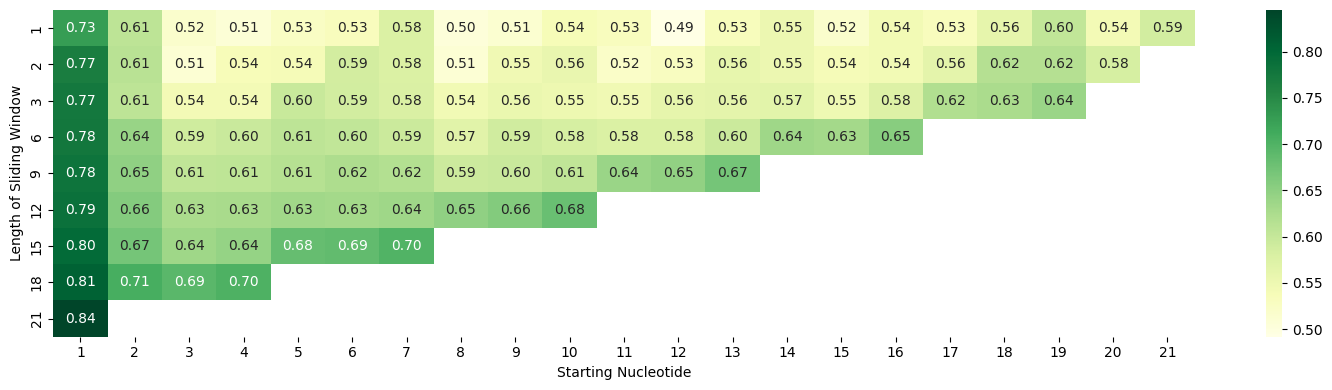

In [14]:

heatmap_data = df_avg.pivot(index="win_len", columns="window_start", values="value")
heatmap_data.index = heatmap_data.index.astype(int)
heatmap_data.columns = heatmap_data.columns.astype(int)

heatmap_data = heatmap_data.sort_index().sort_index(axis=1)

plt.figure(figsize=(15, 4))
sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    annot=True,
    fmt=".2f",  # format (2 decimal places)
)

plt.xlabel("Starting Nucleotide")
plt.ylabel("Length of Sliding Window")
plt.tight_layout()
plt.show()

# Databound Test

In [15]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df.head(2)

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184


In [16]:
filtered_df = df[(df["model"] == "LGR") & (df["representation"] == "zcurve_databound")]

filtered_df["name"] = filtered_df["name"].str.extract(r"^([^_]+)").astype(int)

filtered_df.head(2)

/tmp/ipykernel_2083974/2111086880.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["name"] = filtered_df["name"].str.extract(r"^([^_]+)").astype(int)


,name,representation,model,metric,value
10,50,zcurve_databound,LGR,roc_auc,0.640358
11,50,zcurve_databound,LGR,pr_auc,0.646982


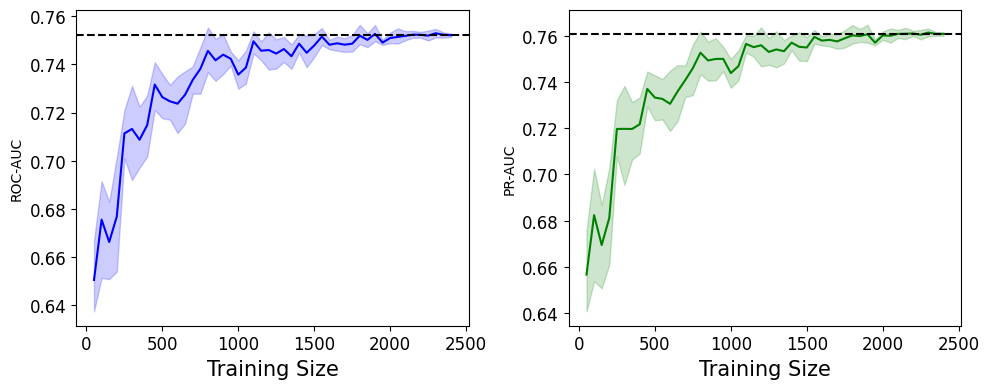

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False, sharex=True)
roc_df = filtered_df[filtered_df["metric"] == "roc_auc"]
sns.lineplot(data=roc_df, x="name", y="value", ax=axes[0], color="Blue", errorbar="ci")
axes[0].axhline(roc_df.loc[roc_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[0].set_xlabel("Training Size", size=15)
axes[0].tick_params(axis="y", labelsize=12)
axes[0].set_ylabel("ROC-AUC")
axes[0].tick_params(axis="x", labelsize=12)
pr_df = filtered_df[filtered_df["metric"] == "pr_auc"]
sns.lineplot(data=pr_df, x="name", y="value", ax=axes[1], color="Green", errorbar="ci")
axes[1].axhline(pr_df.loc[pr_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[1].set_xlabel("Training Size", size=15)
axes[1].tick_params(axis="x", labelsize=12)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].set_ylabel("PR-AUC")
plt.tight_layout()
plt.show()